In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep


In [3]:
# Cargar los DataFrames guardados de los tres canales

# Canal Muones (4mu)
df_data_4mu = pd.read_parquet("df_data_mu.parquet")
df_higgs_4mu = pd.read_parquet("df_higgs_mu.parquet")
df_zz_4mu = pd.read_parquet("df_zz_mu.parquet")

# Canal Mixto (2el2mu)
df_data_mix = pd.read_parquet("df_data_2el2mu.parquet")
df_higgs_mix = pd.read_parquet("df_higgs_2el2mu.parquet")
df_zz_mix = pd.read_parquet("df_zz_2el2mu.parquet")

# Canal Electrones (4el)
df_data_4el = pd.read_parquet("df_data_4el.parquet")
df_higgs_4el = pd.read_parquet("df_higgs_4el.parquet")
df_zz_4el = pd.read_parquet("df_zz_4el.parquet")

In [4]:
# Concatenar los canales para formar un solo conjunto global por cada tipo
df_data_all = pd.concat([df_data_4mu, df_data_4el, df_data_mix], ignore_index=True)
df_higgs_all = pd.concat([df_higgs_4mu, df_higgs_4el, df_higgs_mix], ignore_index=True)
df_zz_all = pd.concat([df_zz_4mu, df_zz_4el, df_zz_mix], ignore_index=True)

# Verificación rápida de los datos combinados
print("Conteo Total de Eventos Combinados")
print(f"Datos reales: {len(df_data_all)}")
print(f"Higgs MC:     {len(df_higgs_all)}")
print(f"Fondo ZZ MC:  {len(df_zz_all)}")

Conteo Total de Eventos Combinados
Datos reales: 204
Higgs MC:     29013
Fondo ZZ MC:  215507


--- Conteo Total Combinado ---
Datos reales totales: 204
Higgs MC total:       29013
Fondo ZZ MC total:    215507
Peso Higgs: 0.000248
Peso ZZ:    8.158652e-04


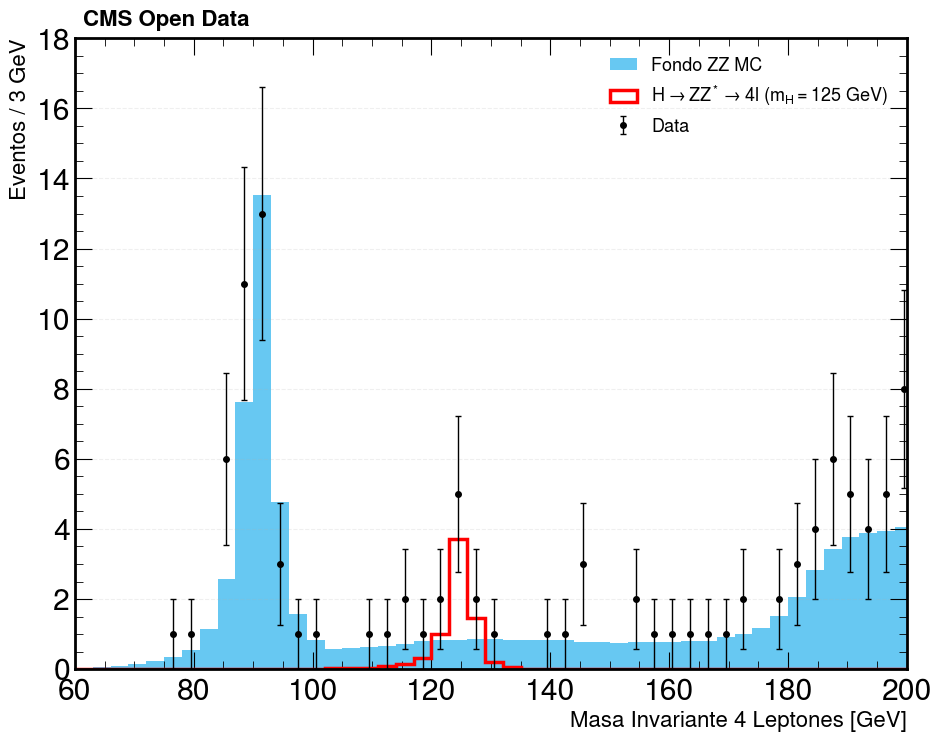

In [5]:
# Estilo CMS
hep.style.use("CMS")

# Cargar los DataFrames de los tres canales desde los archivos Parquet

# Canal Muones (4mu)
df_data_4mu = pd.read_parquet("df_data_mu.parquet")
df_higgs_4mu = pd.read_parquet("df_higgs_mu.parquet")
df_zz_4mu = pd.read_parquet("df_zz_mu.parquet")

# Canal Mixto (2el2mu)
df_data_mix = pd.read_parquet("df_data_2el2mu.parquet")
df_higgs_mix = pd.read_parquet("df_higgs_2el2mu.parquet")
df_zz_mix = pd.read_parquet("df_zz_2el2mu.parquet")

# Canal Electrones (4el)
df_data_4el = pd.read_parquet("df_data_4el.parquet")
df_higgs_4el = pd.read_parquet("df_higgs_4el.parquet")
df_zz_4el = pd.read_parquet("df_zz_4el.parquet")

# Concatenar los canales para formar un solo conjunto global por cada tipo
df_data_all = pd.concat([df_data_4mu, df_data_4el, df_data_mix], ignore_index=True)
df_higgs_all = pd.concat([df_higgs_4mu, df_higgs_4el, df_higgs_mix], ignore_index=True)
df_zz_all = pd.concat([df_zz_4mu, df_zz_4el, df_zz_mix], ignore_index=True)

print("--- Conteo Total Combinado ---")
print(f"Datos reales totales: {len(df_data_all)}")
print(f"Higgs MC total:       {len(df_higgs_all)}")
print(f"Fondo ZZ MC total:    {len(df_zz_all)}")

# Pesos oficiales del CERN
lumi = 11.46 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz = (0.077 * 1.386 * lumi) / 1499064.0

print(f"Peso Higgs: {w_higgs:.6f}")
print(f"Peso ZZ:    {w_zz:.6e}")

# Gráfica con tu estilo personalizado (Bins de 3 GeV)
mis_bins = np.arange(0, 300, 3)

plt.figure(figsize=(10, 8))

# Fondo ZZ MC (Combinado) con estilo de área rellenada
plt.hist(
    df_zz_all["M"],
    bins=mis_bins,
    weights=np.full(len(df_zz_all), w_zz),
    label="Fondo ZZ MC",
    color="#67C8F2",
    histtype="stepfilled",
    alpha=1.0,
)

# Señal de Higgs (Combinado)
plt.hist(
    df_higgs_all["M"],
    bins=mis_bins,
    weights=np.full(len(df_higgs_all), w_higgs),
    label=r"$H \to ZZ^* \to 4l$ ($m_H = 125$ GeV)",
    color="red",
    histtype="step",
    linewidth=2.5,
)

# Datos Reales (Combinado, filtrando ceros para evitar cruces en y=0 si los hubiera)
counts, bin_edges = np.histogram(df_data_all["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
mask_validos = counts > 0

plt.errorbar(
    bin_centers[mask_validos],
    counts[mask_validos],
    yerr=np.sqrt(counts[mask_validos]),
    fmt="o",
    color="black",
    markersize=4,
    capsize=2,
    elinewidth=1,
    linestyle="none",
    label="Data",
)

# Estética y textos de tu preferencia
ax = plt.gca()
ax.text(
    0.01,
    1.02,
    "CMS Open Data",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
    fontstyle="normal",
    ha="left",
)
plt.xlabel("Masa Invariante 4 Leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 3 GeV", fontsize=16)
plt.xlim(60, 200)
plt.ylim(0, 18)

plt.legend(loc="upper right", frameon=False, fontsize=13)
plt.grid(axis="y", alpha=0.2, linestyle="--")
plt.tight_layout()

In [10]:
# Contar filas antes de remover duplicados
antes = len(df_data_all)

# Eliminar duplicados basándose en run, lumi y event (si las columnas están presentes)
columnas_unicas = [col for col in ["run", "lumi", "event"] if col in df_data_all.columns]
if columnas_unicas:
    df_data_all = df_data_all.drop_duplicates(subset=columnas_unicas)
    print(f"Se eliminaron {antes - len(df_data_all)} eventos duplicados.")
else:
    print(
        "Las columnas de identificación (run/event) no están en el DataFrame."
    )

Se eliminaron 0 eventos duplicados.
